In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data you saved
df = pd.read_csv("results/sample_metadata.csv")
expr_df = pd.read_csv("results/expression_matrix.csv", index_col=0)

print(f"Loaded {df.shape[0]} samples, {expr_df.shape[1]} genes")

Loaded 7 samples, 25 genes


In [2]:
# A function to calculate log2 fold change between two groups
def calc_log2fc(expr_df, metadata, gene, group_col, group1, group2):
    """
    Calculate log2 fold change for a gene between two conditions.
    
    Parameters:
        expr_df: expression DataFrame (samples x genes)
        metadata: sample metadata DataFrame
        gene: gene name (string)
        group_col: column name for grouping (string)
        group1: numerator group (string)
        group2: denominator group (string)
    
    Returns:
        log2 fold change (float)
    """
    samples_g1 = metadata[metadata[group_col] == group1]["sample_id"]
    samples_g2 = metadata[metadata[group_col] == group2]["sample_id"]
    
    mean_g1 = expr_df.loc[samples_g1, gene].mean()
    mean_g2 = expr_df.loc[samples_g2, gene].mean()
    
    # Add pseudocount to avoid log(0)
    log2fc = np.log2((mean_g1 + 1) / (mean_g2 + 1))
    return log2fc

# Test it
fc = calc_log2fc(expr_df, df, "ISG15", "condition", "COVID-19", "Healthy")
print(f"ISG15 log2FC (COVID vs Healthy): {fc:.2f}")

ISG15 log2FC (COVID vs Healthy): 1.74


In [3]:
# Calculate log2FC for every gene: COVID vs Healthy
results = []

for gene in expr_df.columns:
    fc = calc_log2fc(expr_df, df, gene, "condition", "COVID-19", "Healthy")
    results.append({"gene": gene, "log2FC": fc})

# Convert to DataFrame and sort
fc_df = pd.DataFrame(results)
fc_df = fc_df.sort_values("log2FC", ascending=False)

print("Top upregulated genes in COVID vs Healthy:")
print(fc_df.head(10).to_string(index=False))

print("\nTop downregulated genes:")
print(fc_df.tail(5).to_string(index=False))

Top upregulated genes in COVID vs Healthy:
  gene   log2FC
  OAS1 2.698207
CXCL10 2.355774
IFITM3 2.296573
IFI44L 2.287298
 RSAD2 2.027896
FCGR3A 1.761236
 ISG15 1.739136
   CD4 1.735012
  GZMB 1.685991
   IL6 1.574314

Top downregulated genes:
   gene    log2FC
   IL10  0.394179
   IL1B  0.221431
    TNF  0.009955
  FOXP3 -0.022846
HLA-DRA -0.117819


In [4]:
# Now let's build a function that does ALL pairwise comparisons at once
def run_all_pairwise(expr_df, metadata, group_col):
    """Run log2FC for all genes across all pairwise group comparisons."""
    groups = metadata[group_col].unique()
    all_results = []
    
    for i, g1 in enumerate(groups):
        for g2 in groups[i+1:]:
            for gene in expr_df.columns:
                fc = calc_log2fc(expr_df, metadata, gene, group_col, g1, g2)
                all_results.append({
                    "gene": gene,
                    "comparison": f"{g1} vs {g2}",
                    "log2FC": fc
                })
    
    return pd.DataFrame(all_results)

# Run it
pairwise_df = run_all_pairwise(expr_df, df, "condition")
print(f"Total comparisons: {pairwise_df.shape[0]}")
print(f"\nComparisons made:")
print(pairwise_df["comparison"].unique())
print(f"\nTop hits per comparison:")
print(pairwise_df.groupby("comparison").apply(
    lambda x: x.nlargest(3, "log2FC")[["gene", "log2FC"]].to_string(index=False)
))

Total comparisons: 75

Comparisons made:
<StringArray>
['COVID-19 vs Influenza', 'COVID-19 vs Healthy', 'Influenza vs Healthy']
Length: 3, dtype: str

Top hits per comparison:
comparison
COVID-19 vs Healthy        gene   log2FC\n  OAS1 2.698207\nCXCL10 2.355...
COVID-19 vs Influenza      gene   log2FC\nFCGR3A 1.163119\n   CD4 0.761...
Influenza vs Healthy       gene   log2FC\n  OAS1 2.415896\n ISG15 2.394...
dtype: str


In [5]:
# Save results to CSV
pairwise_df.to_csv("results/pairwise_log2fc.csv", index=False)
print("Saved pairwise results")

# Read it back (proving the file works)
loaded = pd.read_csv("results/pairwise_log2fc.csv")
print(f"Loaded back: {loaded.shape[0]} rows")

# Write a summary text file
with open("results/analysis_summary.txt", "w") as f:
    f.write("Pairwise Log2FC Analysis Summary\n")
    f.write("=" * 40 + "\n\n")
    f.write(f"Number of genes: {len(expr_df.columns)}\n")
    f.write(f"Number of samples: {len(df)}\n")
    f.write(f"Conditions: {', '.join(df['condition'].unique())}\n\n")
    
    for comparison in pairwise_df["comparison"].unique():
        subset = pairwise_df[pairwise_df["comparison"] == comparison]
        top_gene = subset.loc[subset["log2FC"].idxmax()]
        f.write(f"{comparison}:\n")
        f.write(f"  Top upregulated: {top_gene['gene']} (log2FC = {top_gene['log2FC']:.2f})\n\n")

print("Summary written to results/analysis_summary.txt")

# Read and display
with open("results/analysis_summary.txt", "r") as f:
    print(f.read())

Saved pairwise results
Loaded back: 75 rows
Summary written to results/analysis_summary.txt
Pairwise Log2FC Analysis Summary

Number of genes: 25
Number of samples: 7
Conditions: COVID-19, Influenza, Healthy

COVID-19 vs Influenza:
  Top upregulated: FCGR3A (log2FC = 1.16)

COVID-19 vs Healthy:
  Top upregulated: OAS1 (log2FC = 2.70)

Influenza vs Healthy:
  Top upregulated: OAS1 (log2FC = 2.42)




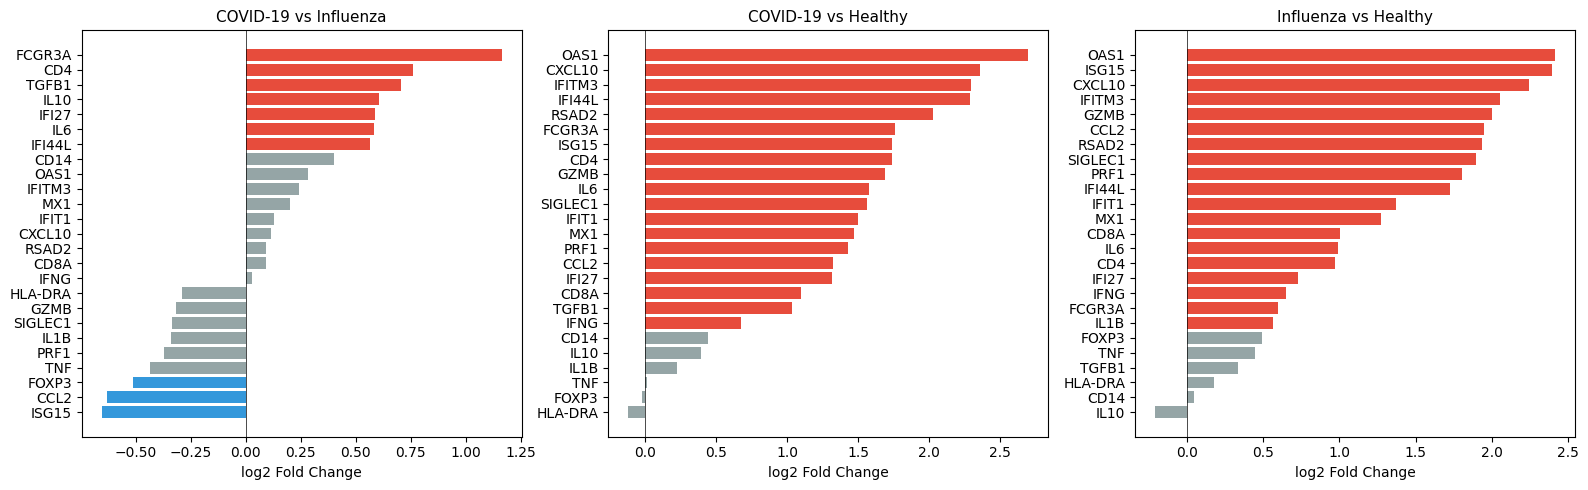

Figure saved!


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, comparison in enumerate(pairwise_df["comparison"].unique()):
    subset = pairwise_df[pairwise_df["comparison"] == comparison].copy()
    subset = subset.sort_values("log2FC")
    
    colors = ["#e74c3c" if x > 0.5 else "#3498db" if x < -0.5 else "#95a5a6" 
              for x in subset["log2FC"]]
    
    axes[i].barh(subset["gene"], subset["log2FC"], color=colors)
    axes[i].set_title(comparison, fontsize=11)
    axes[i].set_xlabel("log2 Fold Change")
    axes[i].axvline(x=0, color="black", linewidth=0.5)

plt.tight_layout()
plt.savefig("figures/04_pairwise_log2fc.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved!")